## IMDB Text Classification with LSTM 

Sentiment analysis classification with Long-Short Term Memory network. 

### Task 1: Understanding the Data

Since we grabbed the data from Kaggle as a csv, we will use the Pandas library to read the csv, then split the data into train and test sets and compute the average, maximum, and minimum review length. 

In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split

imbd_data = pd.read_csv("IMDBDataset.csv")
imbd_data.head()

imbd_data["sentiment"] = imbd_data["sentiment"].map({"positive": 1, "negative": 0}) #change strings of text into labels the model can use to classify

X = imbd_data["review"]
y = imbd_data["sentiment"]

wordCountPerReview = [0] * len(X)

for idx, review in enumerate(X):
    # print(idx, review)
    rev2words = review.split()
    wordCountPerReview[idx] = len(rev2words)
    #if len(rev2words) == 4: print(review)

#print(wordCountPerReview[0:5])
print(f"The average length of a review is {(sum(wordCountPerReview)/len(wordCountPerReview)):.2f}")
print(f"The maximum length of a review is {max(wordCountPerReview)}")
print(f"The minimum length of a review is {min(wordCountPerReview)}")

The average length of a review is 231.16
The maximum length of a review is 2470
The minimum length of a review is 4


Now, keep in mind, we have yet to clean the data of html tags, stop words, punctuation, and text like this "Primary plot!Primary direction!Poor interpretation.", but not much should change in these numbers. Unless of course there were a large number of reviewers that just held down a punctuation key, which would be pretty annoying, however thankfully,  unlikely. 

So, what do these values mean for input sequence length handling in our LSTM model?

These stats tell us how much padding and truncation will be needed so that the model batches have equal length. The minimum review length shows how much padding the shortest reviews are going to need to match the rest. The maximum is the longest review, so padding to it would avoid any truncation but would leave us padding most of the reviews. The average tells us the expected number of timesteps the LSTM will process per review.

For the IMDB dataset, a sequence length a little above the mean is a good compromise. That way most reviews are kept mostly intact, so we lose little text, without the wasted padding that comes from using the max.


### Task 2: Creating a Balanced Validation Split

First we will take the reviews and their associated labels and develop `X_train`, `X_test`, `y_train`, and `y_test`splits whilst keeping the ratios of positive to negative labels equal between test and train. 

Then, we will select `3000` of these samples from the train set to form a validation set such that these samples have equal number of positive and negatie samples.

Then we will print this distribution to illustrate the size of training, validation and test sets after splitting.

In [4]:
import numpy as np

# Splitting the data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.2, # we choose 80/20 train/test split in hopes to train a more confident classification model
    random_state=42, 
    stratify=y  # Keeps equal pos to neg ratio between test and train
)

# Balanced validation split on the training data for 3000 samples
X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=3000,
    random_state=42,
    stratify=y_train
)

print(f"Train input(X) size: {len(X_train)} | Test input(X) size: {len(X_test)}",
      f"\nTrain target(y) size: {len(y_train)} | Test target(y) size: {len(y_test)}",
      f"\nValidation Set size: {len(X_val)}")

def report_distribution(name, y):
    y = np.asarray(y)
    pos = int(np.sum(y == 1))
    neg = int(np.sum(y == 0))
    print(f"{name:<11} | total: {len(y):>6} | positive: {pos:>6} ({pos/len(y):.1%}) | negative: {neg:>6} ({neg/len(y):.1%})")

report_distribution("Train", y_train)
report_distribution("Validation", y_val)
report_distribution("Test", y_test)



Train input(X) size: 37000 | Test input(X) size: 10000 
Train target(y) size: 37000 | Test target(y) size: 10000 
Validation Set size: 3000
Train       | total:  37000 | positive:  18500 (50.0%) | negative:  18500 (50.0%)
Validation  | total:   3000 | positive:   1500 (50.0%) | negative:   1500 (50.0%)
Test        | total:  10000 | positive:   5000 (50.0%) | negative:   5000 (50.0%)


As we can see, we have a balanced dataset. Nice. 

### Task 3: Data Preprocessing

Here we will tackle the instructed preprocessing steps

In [5]:
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer 

nltk.download("stopwords") #Download stop words ntlk data
stop_words = set(stopwords.words("english")) #load into set for quick lookups

stemmer = PorterStemmer() #used for stemming words

from bs4 import BeautifulSoup

def review_to_words(review: pd.Series) -> pd.Series:
    text = review.apply(lambda x: BeautifulSoup(str(x), "html.parser").get_text())
    text = text.str.lower().str.replace(r"[^a-z0-9]", " ", regex=True)
    return text.apply(
        lambda t: " ".join(stemmer.stem(w) for w in t.split() if w not in stop_words)
    )

X_train = review_to_words(X_train) # cleaner data
X_val = review_to_words(X_val)
X_test = review_to_words(X_test)

print("Let's sample a random 5 reviews from our X_train to show off what our reviews look like now: \n ")
for review in X_train.sample(5):
    print(review.split()[:20])
    

[nltk_data] Downloading package stopwords to /home/layden/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Let's sample a random 5 reviews from our X_train to show off what our reviews look like now: 
 
['hey', 'arnold', 'first', 'came', 'air', '1996', 'watch', 'one', 'favorit', 'show', 'episod', 'start', 'get', 'shown', 'got', 'tire', 'wait', 'new', 'episod', 'stop']
['purport', 'documentari', 'tri', 'examin', 'sci', 'fi', 'film', '1950', 'affect', 'reflect', 'america', 'steven', 'spielberg', 'georg', 'luca', 'ridley', 'scott', 'jame', 'cameron', 'interview']
['brave', 'new', 'girl', 'holli', 'come', 'small', 'town', 'texa', 'sing', 'yellow', 'rose', 'texa', 'local', 'competit', 'get', 'admit', 'prestigi', 'art', 'colleg', 'philadelphia']
['game', 'bomb', '007', 'game', 'year', 'greatest', 'hit', 'got', 'agent', 'fire', 'thought', 'good', 'game', 'nightfir', 'came', 'around', 'better', 'new', 'type', 'jame']
['gener', 'film', 'romantic', 'life', 'dublin', 'gangster', 'gener', 'heroic', 'proport', 'made', 'averag', 'dublin', 'person', 'sick', 'along', 'come', 'kevin', 'attempt', 'portray', 

### Task 4: Implementing an LSTM Text Classifier

Now, let's do the real deal. First, we will build a vocabulary from scratch by collecting the most frequent words in the train set, capped at 20,000 (arbitrarily chosen). This will drop rare tokens and building the vocabulary from the train set prevents leakage into the test/val. And we will do some padding for our model to process sequence lengths nicely. 

In [6]:
#Lets encode the data into numbers

from collections import Counter

# To encode the data we first need to build the vocabulary
# we will do this with the training set only, as described above

counter = Counter(w for review in X_train for w in review.split())  # this counts the frequency of each word
print(counter)
MAX_VOCAB = 20_000 
vocab = ["<pad>", "<unk>"] + [w for w,_ in counter.most_common(MAX_VOCAB)] # build the vocab, concatenate <pad> and <unk> in the front
word_to_idx = {w:i for i, w in enumerate(vocab)} # convert the words in the vocab to their correspondent indices
print(word_to_idx)

# this is chosen from the average sizes of the reviews 
# and the comments we previously made about padding and truncating
MAX_LEN = 300 

def encode(tokens, max_len=MAX_LEN):
    ids = [word_to_idx.get(w, 1) for w in tokens][:max_len]   # 1 = <unk>
    return ids + [0] * (max_len - len(ids))                   # 0 = <pad>

X_train_ids = np.array([encode(t.split()) for t in X_train])
X_val_ids   = np.array([encode(t.split()) for t in X_val])
X_test_ids  = np.array([encode(t.split()) for t in X_test])
print((X_train_ids == 1).mean()) # checking that i am encoding words and not characters

print(len(X_train), "\n", len(X_val), "\n", len(X_test))
print(X_train_ids)
print(X_val_ids)
print(X_test_ids)

# sanity check to make sure (X,y) inputs are same length
assert len(X_train_ids) == len(y_train) 
assert len(X_val_ids)   == len(y_val)
assert len(X_test_ids)  == len(y_test)

# checking that a review and its label still match
i = 0
print(y_train.iloc[i], "|", " ".join(vocab[j] for j in X_train_ids[i][:15]))
print(y_train.iloc[i], "|", X_train.iloc[i].split()[:15])

Counter({'movi': 76430, 'film': 71201, 'one': 41070, 'like': 33467, 'time': 23603, 'good': 22394, 'make': 22077, 'charact': 21073, 'see': 20980, 'get': 20688, 'watch': 20562, 'even': 18707, 'stori': 18681, 'would': 18263, 'realli': 17166, 'well': 16100, 'scene': 15962, 'look': 14927, 'show': 14688, 'much': 14285, 'end': 14154, 'bad': 13812, 'peopl': 13579, 'great': 13567, 'go': 13463, 'also': 13456, 'love': 13418, 'think': 13033, 'act': 12996, 'first': 12962, 'play': 12869, 'way': 12712, 'thing': 12189, 'made': 11973, 'could': 11453, 'know': 11248, 'say': 11147, 'seem': 10392, 'work': 10359, 'plot': 10165, 'actor': 10098, 'two': 10009, 'mani': 9968, 'seen': 9950, 'come': 9881, 'year': 9797, 'want': 9779, 'take': 9617, 'never': 9572, 'life': 9556, 'best': 9427, 'littl': 9271, 'tri': 9220, 'ever': 8930, 'man': 8728, 'give': 8480, 'better': 8468, 'still': 8123, 'find': 8029, 'perform': 7985, 'use': 7668, 'feel': 7599, 'part': 7596, 'someth': 7528, 'director': 7478, 'actual': 7451, 'back':

And now we have encoded text data we can train!

Now, we can design our LSTM with a hidden size of 128, 2 LSTM layers, and the Adam optimizer. A hidden size of 128 gives the model enough memory to capture sentiment cues like negations without overfitting our ~37,000 training reviews, since larger sizes grow the parameter count quickly. We use 2 layers so the second layer can build higher-level features on top of the first layer's output, such as combining individual word cues into phrase-level sentiment, with dropout of 0.3 between the layers to limit overfitting from the added capacity. We use Adam because it adapts the learning rate per parameter, converging faster than plain SGD with little tuning, with 1e-3 as a standard starting learning rate.

In [7]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

class SentimentLSTM(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, output_dim, num_layers, dropout):
        super(SentimentLSTM, self).__init__()
        
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        
        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout
        )
        
        self.fc = nn.Linear(hidden_dim, output_dim)
        self.dropout = nn.Dropout(dropout)
        
    def forward(self, x):
        embedded = self.embedding(x)
        
        lstm_out, (hidden, cell) = self.lstm(embedded)
        
        out = self.dropout(hidden[-1])
        out = self.fc(out)
        
        return out.squeeze(1)

class IMDBDataset(Dataset): # convert reviews and labels into a readable dataset for dataloader
    def __init__(self, sequences, labels):
        self.sequences = self.is_numpy(sequences)
        self.labels = self.is_numpy(labels)
        
    def __len__(self):
        return len(self.sequences)
    
    def __getitem__(self, idx):
        x = torch.tensor(self.sequences[idx], dtype=torch.long)
        y = torch.tensor(self.labels[idx], dtype=torch.float32)
        return x, y

    def is_numpy(self, arr): # keep from data being pd.Series type (avoiding keyerror bug i keep getting)
        return arr if isinstance(arr, np.ndarray) else arr.to_numpy()

BATCH_SIZE = 64
train_dataset = IMDBDataset(X_train_ids, y_train)
val_dataset = IMDBDataset(X_val_ids, y_val)
test_dataset = IMDBDataset(X_test_ids, y_test)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)


print("Train size:", len(train_dataset))
print("Validation size:", len(val_dataset))
print("Test size:", len(test_dataset))

VOCAB_SIZE = len(vocab)
EMBEDDING_DIM = 128
HIDDEN_DIM = 128
OUTPUT_DIM = 1
NUM_LAYERS = 2
DROPOUT = 0.3
device = "mps" if torch.backends.mps.is_available() else "cpu"

model = SentimentLSTM(
    vocab_size=VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    output_dim=OUTPUT_DIM,
    num_layers=NUM_LAYERS,
    dropout=DROPOUT
).to(device)

print(model)

Train size: 37000
Validation size: 3000
Test size: 10000
SentimentLSTM(
  (embedding): Embedding(20002, 128, padding_idx=0)
  (lstm): LSTM(128, 128, num_layers=2, batch_first=True, dropout=0.3)
  (fc): Linear(in_features=128, out_features=1, bias=True)
  (dropout): Dropout(p=0.3, inplace=False)
)


In [9]:
# Now let's train the model
import time
import copy
import torch.optim as optim

alpha = 1e-3
criterion = nn.BCEWithLogitsLoss() # binary cross entropy bc binary classification between pos/neg reviews (1/0)
optimizer = optim.Adam(model.parameters(), lr=alpha) # using Adam, reaches optimum faster with momentum

def binary_accuracy(preds, y):
    probs = torch.sigmoid(preds) # convert model prediction to prob
    rounded = torch.round(probs) # round to nearest integer 0 or 1
    correct = (rounded == y).float() # convert correctly predicted model output to 1's and 0's

    return correct.sum() / len(correct) # get the accuracy

def train_one_epoch(model, loader, criterion, optimizer, device): #train an epoch
    model.train()
    
    epoch_loss = 0
    epoch_acc = 0
    
    for reviews, labels in loader:
        # if mps available, load to that
        reviews = reviews.to(device)
        labels = labels.to(device)
        
        optimizer.zero_grad() # zero out the gradients at the beginning of every new forward pass
        
        outputs = model(reviews) 
        loss = criterion(outputs, labels) # compute loss
        acc = binary_accuracy(outputs, labels) #get accuracy
        
        loss.backward() # calculate slope at current position
        optimizer.step() #update weights

        # accumulate loss and accuracy
        epoch_loss += loss.item()
        epoch_acc += acc.item()
    
    return epoch_loss / len(loader), epoch_acc / len(loader) # return loss and acc

def evaluate(model, loader, criterion, device): #evaluate an epoch
    # same stuff as train but now we evaluate 
    model.eval()
    
    epoch_loss = 0
    epoch_acc = 0
    
    with torch.no_grad(): # down compute gradients when evaluating performance of nn parameters
        for reviews, labels in loader:
            reviews = reviews.to(device)
            labels = labels.to(device)
            
            outputs = model(reviews)
            loss = criterion(outputs, labels)
            acc = binary_accuracy(outputs, labels)
            
            epoch_loss += loss.item()
            epoch_acc += acc.item()
    
    return epoch_loss / len(loader), epoch_acc / len(loader) 



def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs):
    best_model_wts = copy.deepcopy(model.state_dict()) # get best model weights
    best_val_loss = float("inf") # track best val_loss
    
    history = { # collect history for plots for performance on train/val loss and accuracy
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": [],
        "epoch_time": []
    }
    
    for epoch in range(num_epochs):
        start_time = time.time()
        
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc = evaluate(model, val_loader, criterion, device)
        
        epoch_time = time.time() - start_time
        
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["epoch_time"].append(epoch_time)
        
        print(f"Epoch {epoch+1}/{num_epochs}")
        print(f"Train Loss : {train_loss:.4f} | Train Acc : {train_acc:.4f}")
        print(f"Val Loss   : {val_loss:.4f} | Val Acc   : {val_acc:.4f}")
        print(f"Epoch Time : {epoch_time:.2f} sec")
        print("-" * 50)
        
        if val_loss < best_val_loss: #update best val loss
            best_val_loss = val_loss
            best_model_wts = copy.deepcopy(model.state_dict())
            torch.save(model.state_dict(), "best_sentiment_lstm.pth")
            print("Best model saved.\n")
    
    model.load_state_dict(best_model_wts) #keep best weights
    return model, history

# Let's start off with 5 epochs and train the model here
NUM_EPOCHS = 8

model, history = train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    NUM_EPOCHS
)

Epoch 1/8
Train Loss : 0.6933 | Train Acc : 0.5013
Val Loss   : 0.6930 | Val Acc   : 0.5049
Epoch Time : 77.65 sec
--------------------------------------------------
Best model saved.

Epoch 2/8
Train Loss : 0.6901 | Train Acc : 0.5089
Val Loss   : 0.6944 | Val Acc   : 0.5092
Epoch Time : 77.70 sec
--------------------------------------------------
Epoch 3/8
Train Loss : 0.6809 | Train Acc : 0.5200
Val Loss   : 0.6968 | Val Acc   : 0.5017
Epoch Time : 75.90 sec
--------------------------------------------------
Epoch 4/8
Train Loss : 0.6644 | Train Acc : 0.5415
Val Loss   : 0.6950 | Val Acc   : 0.5115
Epoch Time : 75.56 sec
--------------------------------------------------
Epoch 5/8
Train Loss : 0.6202 | Train Acc : 0.6410
Val Loss   : 0.6299 | Val Acc   : 0.6534
Epoch Time : 77.19 sec
--------------------------------------------------
Best model saved.

Epoch 6/8
Train Loss : 0.5814 | Train Acc : 0.7081
Val Loss   : 0.6339 | Val Acc   : 0.6648
Epoch Time : 77.75 sec
-----------------

And here we have a validation accuracy of about 84%. Nice! 

Now that we have trained the model, let's take a look at the train/validation performance for different LSTM layers. Our initial training used 2 LSTM layers. But let's see what happens if we only had one, or even 3. We will do this by first training the model with the different layers and then plot the change in loss/accuracy afterwards using plots. 

In [10]:

# To do this we are going to need a function that trains with fresh weights for each model layer. This is simple, we will just build a model for each run
def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs, numlayers):
    best_model_wts = copy.deepcopy(model.state_dict()) # get best model weights
    best_val_loss = float("inf") # track best val_loss
    numlayers= numlayers
    history = { # collect history for plots for performance on train/val loss and accuracy
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": [],
        "epoch_time": []
    }
    
    for epoch in range(num_epochs):
        start_time = time.time()
        
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc = evaluate(model, val_loader, criterion, device)
        
        epoch_time = time.time() - start_time
        
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["epoch_time"].append(epoch_time)
        
        print(f"Epoch {epoch+1}/{num_epochs}")
        print(f"Train Loss : {train_loss:.4f} | Train Acc : {train_acc:.4f}")
        print(f"Val Loss   : {val_loss:.4f} | Val Acc   : {val_acc:.4f}")
        print(f"Epoch Time : {epoch_time:.2f} sec")
        print("-" * 50)
        
        if val_loss < best_val_loss: #update best val loss
            best_val_loss = val_loss
            best_model_wts = copy.deepcopy(model.state_dict())
            torch.save(model.state_dict(), f"best_lstm_{numlayers}.pth")
            print("Best model saved.\n")
    
    model.load_state_dict(best_model_wts) #keep best weights
    return model, history

def run_experiment(num_layers: int, epochs=8):
    torch.manual_seed(42)
    dropout = 0 if num_layers == 1 else 0.3  # this is going to cause error if not set to zero for one layer. 

    model = SentimentLSTM(len(vocab), EMBEDDING_DIM, HIDDEN_DIM, OUTPUT_DIM,
                          num_layers=num_layers, dropout=dropout)
    optimizer = optim.Adam(model.parameters(), lr=alpha)   # fresh optimizer for each new model

    model, history = train_model(model, train_loader, val_loader, criterion,
                                 optimizer, epochs, num_layers)
    return history

results = {n: run_experiment(n) for n in [1, 2, 3]}
print(f"{'Layers':<8}{'Time (m:s)':<15}{'Best val acc':<15}{'Final train acc':<17}{'Gap (train-val)'}")
for n, h in results.items():
    best_val = max(h["val_acc"])
    final_train = h["train_acc"][-1]
    minutes, seconds = divmod(int(sum(h["epoch_time"])), 60)
    time_str = f"{minutes}:{seconds:02d}"
    print(f"{n:<8}{time_str:<15}{best_val:<15.4f}{final_train:<17.4f}{final_train - h['val_acc'][-1]:.4f}")


Epoch 1/8
Train Loss : 0.6934 | Train Acc : 0.5016
Val Loss   : 0.6926 | Val Acc   : 0.4974
Epoch Time : 37.12 sec
--------------------------------------------------
Best model saved.

Epoch 2/8
Train Loss : 0.6919 | Train Acc : 0.5091
Val Loss   : 0.6926 | Val Acc   : 0.5096
Epoch Time : 34.54 sec
--------------------------------------------------
Epoch 3/8
Train Loss : 0.6812 | Train Acc : 0.5198
Val Loss   : 0.6977 | Val Acc   : 0.4951
Epoch Time : 33.68 sec
--------------------------------------------------
Epoch 4/8
Train Loss : 0.6652 | Train Acc : 0.5222
Val Loss   : 0.7045 | Val Acc   : 0.5092
Epoch Time : 32.44 sec
--------------------------------------------------
Epoch 5/8
Train Loss : 0.6561 | Train Acc : 0.5322
Val Loss   : 0.7072 | Val Acc   : 0.5118
Epoch Time : 32.47 sec
--------------------------------------------------
Epoch 6/8
Train Loss : 0.6662 | Train Acc : 0.5382
Val Loss   : 0.6978 | Val Acc   : 0.4981
Epoch Time : 32.38 sec
------------------------------------

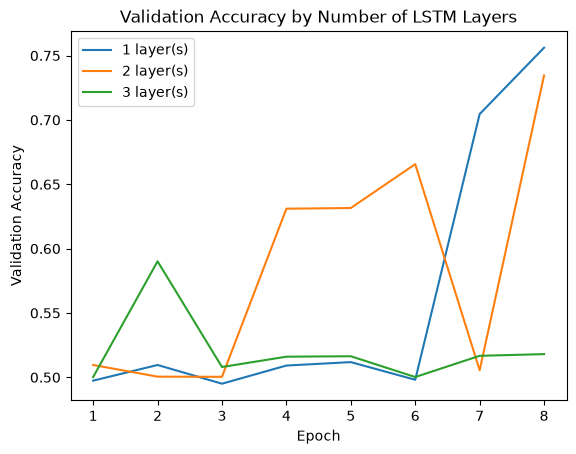

In [12]:
# Now let's plot our results
import matplotlib.pyplot as plt

for n, h in results.items():
    plt.plot(range(1, len(h["val_acc"]) + 1), h["val_acc"], label=f"{n} layer(s)")
plt.xlabel("Epoch"); plt.ylabel("Validation Accuracy")
plt.title("Validation Accuracy by Number of LSTM Layers")
plt.legend(); plt.show()

And it seems that one layer on the LSTM network performed better on validation accuracy than the other two, interesting. 

### Task 5: Performance Evaluation



Notice that the LSTM model with one layer performed best in our test for 1-3. This is interesting and not expected in my opinion. It seems that it might be overfitting on attempting to learn hierarchical representations of the sequential data and capture long-term dependencies more effectively. But this isn't needed, for we are mapping embeddings of text to positive/negative sentiment. However, I will do the performance evaluation on the initial model with 2 layers, considering that it had a best validation accuracy at about 84%. So, let's report the accuracy, precision, recall, F1-Score, and AUC score. 

In [24]:

best_model = SentimentLSTM(len(vocab), EMBEDDING_DIM, HIDDEN_DIM, OUTPUT_DIM,
                           num_layers=2,
                           dropout=DROPOUT).to(device) # matching architecture of layer 2 lstm model

best_model.load_state_dict(torch.load("best_sentiment_lstm.pth", map_location=device)) # load that model and its weights
best_model.eval() # prepare for evaluation

test_loss, test_acc = evaluate(best_model, test_loader, criterion, device) # evaluate with our function
print(f"Test Loss: {test_loss:.4f} | Test Acc: {test_acc:.4f}") #print those results

#let's also check with our binary accuracy function
best_model.eval()

X_test_t = torch.tensor(X_test_ids, dtype=torch.long).to(device)
y_test_t = torch.tensor(y_test.to_numpy(), dtype=torch.float32).to(device)

with torch.no_grad():
    outputs = best_model(X_test_t)

test_binacc = binary_accuracy(outputs, y_test_t)
print(f"Test accuracy (binary_accuracy): {test_binacc.item():.4f}")

Test Loss: 0.3729 | Test Acc: 0.8422
Test accuracy (binary_accuracy): 0.8423


In [11]:
# Now let's compute the accuracy, precision, recall, f1 score and AUC with sklearn

import numpy as np
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)

best_model.eval()
all_probs, all_labels = [], []

with torch.no_grad():
    for x, y in test_loader: #iterate through test loader review to sentiment data
        logits = best_model(x.to(device)) # outputs to the reviews are logits  
        all_probs.append(torch.sigmoid(logits).cpu()) #append the sigmoid(review_logit) to the list
        all_labels.append(y) # along with its associated label

probs  = torch.cat(all_probs).numpy() # torch.cat joins tensors along row dimensions
labels = torch.cat(all_labels).numpy()
preds  = (probs > 0.5).astype(int)

print(f"Accuracy : {accuracy_score(labels, preds):.4f}")
print(f"Precision: {precision_score(labels, preds):.4f}")
print(f"Recall   : {recall_score(labels, preds):.4f}")
print(f"F1 score : {f1_score(labels, preds):.4f}")
print(f"AUC      : {roc_auc_score(labels, probs):.4f}")   # probabilities, not rounded preds
print(confusion_matrix(labels, preds))

Accuracy : 0.8423
Precision: 0.8613
Recall   : 0.8160
F1 score : 0.8380
AUC      : 0.9192
[[4343  657]
 [ 920 4080]]


That is almost a one on AUC. That is pretty good. Our confusion matrix is set up like this in sklearn `[[TN, FP], [FN, TP]]`. So, this means that 4,343 are true negatives (negative reviews correctly classified as negative), 657 are false positive (positive reviews incorrectly classified as negative), 920 are false negatives (positive reviews incorrectly classified as negative), and 4080 are true positives (poisitive reviews correctly classified as positive). 

The AUC (Area Under the ROC Curve) tells us that if we randomly sample a positive review, it will correctly rank that sample higher than a negative chosen sample with 91% probability. That is pretty good. 

So, now that we have this information, let's see if our model can predict if a sample review is negative or positive. 

In [27]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r"<.*?>", " ", text)
    text = re.sub(r"[^a-zA-Z]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

def pad_sequence(sequence, max_len):
    if len(sequence) < max_len:
        sequence = sequence + [0] * (max_len - len(sequence))
    else:
        sequence = sequence[:max_len]
    return sequence

def predict_sentiment(review, model, word2idx, max_len, device):
    model.eval()
    
    review = clean_text(review)
    tokens = review.split()
    sequence = [word2idx.get(token, word2idx["<unk>"]) for token in tokens]
    padded = pad_sequence(sequence, max_len)
    
    tensor = torch.tensor(padded, dtype=torch.long).unsqueeze(0).to(device)
    
    with torch.no_grad():
        output = model(tensor)
        prob = torch.sigmoid(output).item()
    
    sentiment = "positive" if prob >= 0.5 else "negative"
    
    return sentiment, prob

sample_review = X.sample(n=1).iloc[0] # sample a review randomly from our initial pandas csv and grab just the review string and not the index

sentiment, prob = predict_sentiment(sample_review, model, word_to_idx, MAX_LEN, device)

print("Review:", sample_review)
print("Predicted Sentiment:", sentiment)
print("Probability:", prob)

Review: This is one of those movies where you have to put to one side some of its obvious shortcomings (a result of the date and location of its production)and accentuate the positive. In many ways this is a truly superb film.<br /><br />Forgive the parody in the one line summary, but the most serious shortcoming for an English speaker like me was the ghastly subtitles. The print I saw had 1982 Soviet "Film Export" subtitles, which consistently used inverted grammar, presumably to give the impression of 13th century speech. The actual impact of this nonsense is to make it harder to follow the subtitles which means you spend less time looking at the images. Given that the cinematographic imagery is this films great strength, this is a real issue.<br /><br />Other IMDB-niks have written plenty about the Stalinist propaganda elements of this film (just in case the viewer doesn't notice them for him/herself). They have also written plenty about the battle on the ice scene, which is superb 

This is neat. Not a bad model either. 

Play around with this and see how it predicts the sentiment for each review from our dataset. I wonder if it performs well on unseen data? 